# Tâche 1: Calcul TF-IDF et Classification de Sentiment

La première tâche consistait à structurer les données en définissant une liste d’avis textuels accompagnés de leurs étiquettes réelles, indiquant si chaque avis est positif ou négatif. Ensuite, un vocabulaire a été établi en extrayant les mots clés les plus pertinents des avis. Ce vocabulaire servira à transformer les textes en une représentation numérique sous forme de matrice TF-IDF, essentielle pour entraîner et tester le modèle de classification.

In [7]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

# Définir les avis
avis = [
    "The plot is predictable without excitement, won't recommend",        # R1
    "The novel has an interesting plot and story",                        # R2
    "The story is fast-paced, filled with excitement, would recommend",   # R3
    "The plot is predictable, the story is unconvincing"                  # R4
]

# Définir les étiquettes réelles
y_true = np.array([0, 1, 1, 0])  # 0=Négative, 1=Positive

# Définir le vocabulaire
vocabulaire = ['plot', 'predictable', 'without', 'excitement', "won't", 'recommend',
              'novel', 'story', 'interesting', 'fast-paced', 'filled', 'unconvincing']

# Partie 1(a): Créer manuellement la matrice TF-IDF avec les valeurs exactes du document
# Matrice TF-IDF avec 4 documents (lignes) et 12 termes (colonnes)
X_tfidf = np.zeros((4, 12))

# R1: predictable, without, excitement, won't, recommend
X_tfidf[0, 1] = 0.3010  # predictable
X_tfidf[0, 2] = 0.6020  # without
X_tfidf[0, 3] = 0.3010  # excitement
X_tfidf[0, 4] = 0.6020  # won't
X_tfidf[0, 5] = 0.3010  # recommend

# R2: novel, story, interesting
X_tfidf[1, 6] = 0.6020  # novel
X_tfidf[1, 7] = 0.1249  # story
X_tfidf[1, 8] = 0.6020  # interesting

# R3: excitement, recommend, story, fast-paced, filled
X_tfidf[2, 3] = 0.3010  # excitement
X_tfidf[2, 5] = 0.3010  # recommend
X_tfidf[2, 7] = 0.1249  # story
X_tfidf[2, 9] = 0.6020  # fast-paced
X_tfidf[2, 10] = 0.6020  # filled

# R4: predictable, story, unconvincing
X_tfidf[3, 1] = 0.3010  # predictable
X_tfidf[3, 7] = 0.1249  # story
X_tfidf[3, 11] = 0.6020  # unconvincing

# Afficher la matrice TF-IDF
tfidf_df = pd.DataFrame(X_tfidf, columns=vocabulaire, index=['R1', 'R2', 'R3', 'R4'])
print("Matrice TF-IDF:")
print(tfidf_df.round(4))
print("\n")

# Partie 1(b): Prédiction avec Régression Logistique
# Définir les poids du modèle pré-entraîné
w = np.array([0.5, -0.2, -0.3, 1.5, -0.3, 1.1, 0.9, 0.8, 1.3, 1.7, 0.1, -0.4])

# Calculer le produit scalaire pour chaque avis
scores = X_tfidf @ w

# Fonction sigmoïde
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Calculer les probabilités
probas = sigmoid(scores)

# Prédire les classes
predictions = (probas > 0.5).astype(int)

# Afficher les résultats
results_df = pd.DataFrame({
    'Score': scores.round(4),
    'Probabilité': probas.round(4),
    'Prédiction': predictions,
    'Étiquette réelle': y_true
}, index=['R1', 'R2', 'R3', 'R4'])
print("Résultats de la classification:")
print(results_df)
print("\n")

# Partie 1(c): Calcul de la perte d'entropie croisée
# Calculer la perte pour chaque avis
losses = []
for i in range(len(y_true)):
    if y_true[i] == 1:
        loss = -np.log(probas[i])
    else:
        loss = -np.log(1 - probas[i])
    losses.append(loss)

# Calculer la perte moyenne
losses = np.array(losses)
mean_loss = np.mean(losses)

print("Pertes d'entropie croisée:")
losses_df = pd.DataFrame({
    'Perte': losses.round(4)
}, index=['R1', 'R2', 'R3', 'R4'])
print(losses_df)
print(f"Perte moyenne: {mean_loss:.4f}")
print("\n")

# Partie 1(d): Prédiction pour un nouvel avis
# Créer manuellement le vecteur TF-IDF pour le nouvel avis selon les calculs du document
nouvel_avis_tfidf = np.zeros(12)
nouvel_avis_tfidf[3] = 0.3010  # excitement
nouvel_avis_tfidf[5] = 0.3010  # recommend
nouvel_avis_tfidf[7] = 0.1249  # story
nouvel_avis_tfidf[10] = 0.6020  # filled

# Calculer le score
nouvel_score = nouvel_avis_tfidf @ w

# Calculer la probabilité
nouvel_proba = sigmoid(nouvel_score)

# Prédire la classe
nouvelle_prediction = 1 if nouvel_proba > 0.5 else 0

print(f"Prédiction pour le nouvel avis:")
print(f"Score: {nouvel_score:.4f}")
print(f"Probabilité: {nouvel_proba:.4f}")
print(f"Prédiction: {'Positive' if nouvelle_prediction == 1 else 'Négative'}")

Matrice TF-IDF:
    plot  predictable  without  excitement  won't  recommend  novel   story  \
R1   0.0        0.301    0.602       0.301  0.602      0.301  0.000  0.0000   
R2   0.0        0.000    0.000       0.000  0.000      0.000  0.602  0.1249   
R3   0.0        0.000    0.000       0.301  0.000      0.301  0.000  0.1249   
R4   0.0        0.301    0.000       0.000  0.000      0.000  0.000  0.1249   

    interesting  fast-paced  filled  unconvincing  
R1        0.000       0.000   0.000         0.000  
R2        0.602       0.000   0.000         0.000  
R3        0.000       0.602   0.602         0.000  
R4        0.000       0.000   0.000         0.602  


Résultats de la classification:
     Score  Probabilité  Prédiction  Étiquette réelle
R1  0.3612       0.5893           1                 0
R2  1.4243       0.8060           1                 1
R3  1.9661       0.8772           1                 1
R4 -0.2011       0.4499           0                 0


Pertes d'entropie croi

# Tâche 2: Classification de Sentiment avec Vecteurs Denses

La deuxième tâche consiste à effectuer une prédiction à l'aide de régression logistique avec des vecteurs denses. Le processus commence par définir les vecteurs denses pour chaque avis et compiler ces vecteurs dans une matrice. Ensuite, un vecteur de poids est appliqué aux avis pour calculer un score pour chaque observation. Ce score est ensuite transformé en probabilité à l'aide de la fonction sigmoïde. En fonction de cette probabilité, une classe (positive ou négative) est prédite.

La perte d'entropie croisée est calculée pour évaluer la performance du modèle. Enfin, une prédiction est effectuée pour un nouvel avis en utilisant le même processus de calcul du score et de la probabilité.

In [2]:
import numpy as np
import pandas as pd

# Définir les vecteurs denses pour chaque avis
R1 = np.array([0.58, -0.48, 0.65, -1.35, 1.85])
R2 = np.array([-0.61, 1.97, -1.06, 0.34, -0.37])
R3 = np.array([-1.46, 0.18, 0.07, 1.07, 1.74])
R4 = np.array([-1.64, -1.22, 1.98, -1.06, -1.04])

# Compiler les vecteurs dans une matrice
X_dense = np.vstack([R1, R2, R3, R4])

# Définir les étiquettes réelles
y_true = np.array([0, 1, 1, 0])  # 0=Négative, 1=Positive

# Partie 2(a): Processus de prédiction avec régression logistique
# Définir le vecteur de poids
w = np.array([-0.3, 1.8, 0.9, 1.5, -0.1])

# Calculer le produit scalaire pour chaque avis
scores = X_dense @ w

# Fonction sigmoïde
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Calculer les probabilités
probas = sigmoid(scores)

# Prédire les classes
predictions = (probas > 0.5).astype(int)

# Afficher les résultats du modèle
results_df = pd.DataFrame({
    'Score': scores.round(4),
    'Probabilité': probas.round(4),
    'Prédiction': predictions,
    'Étiquette réelle': y_true
}, index=['R1', 'R2', 'R3', 'R4'])

print("Résultats de la classification avec vecteurs denses:")
print(results_df)
print("\n")

# Partie 2(b): Calcul de la perte d'entropie croisée
# Calculer la perte pour chaque avis
losses = []
for i in range(len(y_true)):
    if y_true[i] == 1:
        loss = -np.log(probas[i])
    else:
        loss = -np.log(1 - probas[i])
    losses.append(loss)

# Calculer la perte moyenne
mean_loss = np.mean(losses)

print("Pertes d'entropie croisée:")
losses_df = pd.DataFrame({
    'Perte': np.round(losses, 4)
}, index=['R1', 'R2', 'R3', 'R4'])
print(losses_df)
print(f"Perte moyenne: {mean_loss:.4f}")
print("\n")

# Partie 2(c): Prédiction pour un nouveau vecteur
nouveau_vecteur = np.array([0.52, 0.94, 0.75, -1.88, 1.61])

# Calculer le score
nouveau_score = nouveau_vecteur @ w

# Calculer la probabilité
nouvelle_proba = sigmoid(nouveau_score)

# Prédire la classe
nouvelle_prediction = 1 if nouvelle_proba > 0.5 else 0

print(f"Prédiction pour le nouveau vecteur:")
print(f"Score: {nouveau_score:.4f}")
print(f"Probabilité: {nouvelle_proba:.4f}")
print(f"Prédiction: {'Positive' if nouvelle_prediction == 1 else 'Négative'}")

Résultats de la classification avec vecteurs denses:
    Score  Probabilité  Prédiction  Étiquette réelle
R1 -2.663       0.0652           0                 0
R2  3.322       0.9652           1                 1
R3  2.256       0.9052           1                 1
R4 -1.408       0.1965           0                 0


Pertes d'entropie croisée:
     Perte
R1  0.0674
R2  0.0354
R3  0.0996
R4  0.2188
Perte moyenne: 0.1053


Prédiction pour le nouveau vecteur:
Score: -0.7700
Probabilité: 0.3165
Prédiction: Négative


# Tâche 3: Comparaison entre TF-IDF et Vecteurs Denses

La troisième tâche est une comparaison :

1. **Analyse TF-IDF** :
   - Un vecteur TF-IDF est calculé à partir d'un vocabulaire défini.
   - Les scores et probabilités sont calculés, puis la perte d'entropie croisée est obtenue.
   
2. **Analyse avec vecteurs denses** :
   - Un modèle basé sur des vecteurs denses est utilisé pour calculer les scores et probabilités.
   - La perte d'entropie croisée est également calculée pour cette approche.

3. **Comparaison des résultats** :
   - Un tableau comparatif est créé pour afficher les probabilités, prédictions et pertes pour chaque avis.
   - Les précisions et pertes moyennes des deux modèles sont comparées.

4. **Analyse textuelle des différences** :
   - Une analyse est réalisée sur les différences entre les approches TF-IDF et vecteurs denses, concernant leur nature, performance, et applications optimales.

/usr/local/lib/python3.11/dist-packages/sklearn/feature_extraction/text.py:1675: RuntimeWarning: divide by zero encountered in divide
  self.idf_ /= df


Tableau comparatif des deux approches:
    Probas TF-IDF  Preds TF-IDF  Perte TF-IDF  Probas Vecteurs Denses  \
R1         0.9819             1        4.0098                  0.0652   
R2         0.9990             1        0.0010                  0.9652   
R3         0.9966             1        0.0034                  0.9052   
R4         0.5941             1        0.9016                  0.1965   

    Preds Vecteurs Denses  Perte Vecteurs Denses  Étiquette réelle  
R1                      0                 0.0674                 0  
R2                      1                 0.0354                 1  
R3                      1                 0.0996                 1  
R4                      0                 0.2188                 0  

Perte moyenne TF-IDF: 1.2290
Perte moyenne Vecteurs Denses: 0.1053

Précision TF-IDF: 0.5000
Précision Vecteurs Denses: 1.0000


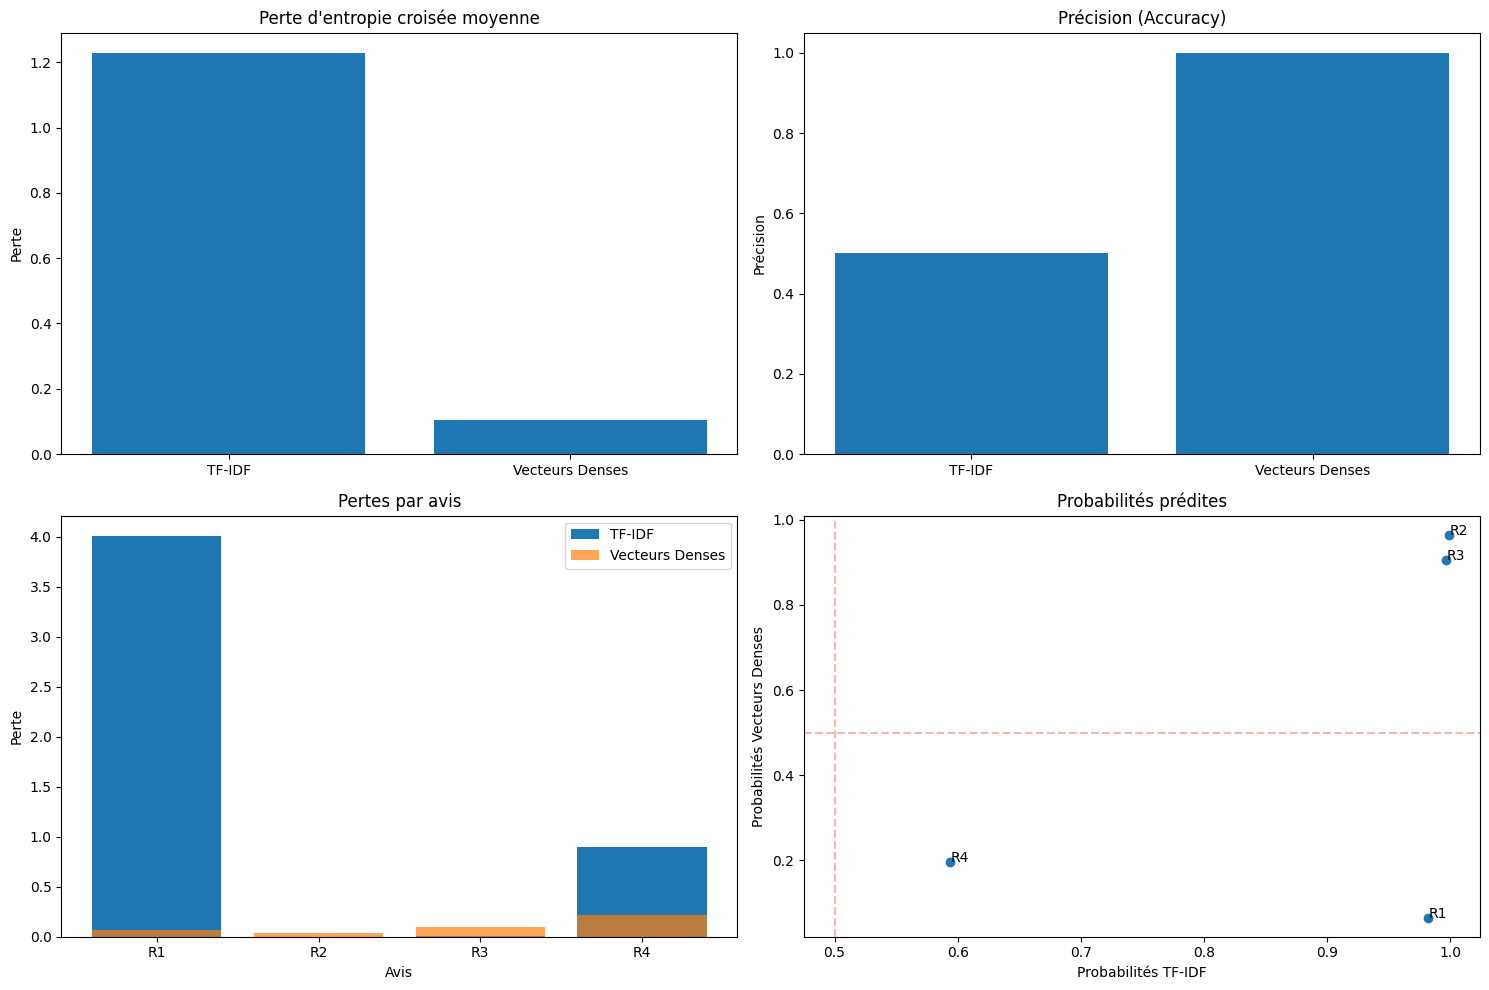


Comparaison des approches TF-IDF et Vecteurs Denses pour la classification de sentiment:

1. Nature de la représentation:
   TF-IDF : Représentation creuse basée sur la fréquence des termes et leur importance dans le corpus
   Vecteurs Denses : Représentation compacte de dimension fixe capturant des concepts sémantiques

2. Capture sémantique:
   TF-IDF : Ne capture que la présence/absence des mots sans relations sémantiques
   Vecteurs Denses : Capture les relations sémantiques entre mots et concepts

3. Performance:
   TF-IDF : Perte moyenne = 1.2290, Précision = 0.5000
   Vecteurs Denses : Perte moyenne = 0.1053, Précision = 1.0000

4. Applications optimales:
   TF-IDF : Recherche par mots-clés, classification avec vocabulaire spécifique
   Vecteurs Denses : Applications nécessitant une compréhension du contexte et des nuances


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, log_loss

# Définir les données
avis = [
    "The plot is predictable without excitement, won't recommend",  # R1
    "The novel has an interesting plot and story",                  # R2
    "The story is fast-paced, filled with excitement, would recommend",  # R3
    "The plot is predictable, the story is unconvincing"            # R4
]

# Vecteurs denses
vecteurs_denses = np.array([
    [0.58, -0.48, 0.65, -1.35, 1.85],   # R1
    [-0.61, 1.97, -1.06, 0.34, -0.37],  # R2
    [-1.46, 0.18, 0.07, 1.07, 1.74],    # R3
    [-1.64, -1.22, 1.98, -1.06, -1.04]  # R4
])

# Étiquettes réelles
y_true = np.array([0, 1, 1, 0])  # 0=Négative, 1=Positive

# Fonction sigmoïde
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Fonction pour calculer la perte d'entropie croisée
def cross_entropy_loss(y_true, y_pred):
    losses = []
    for i in range(len(y_true)):
        if y_true[i] == 1:
            loss = -np.log(y_pred[i])
        else:
            loss = -np.log(1 - y_pred[i])
        losses.append(loss)
    return np.array(losses), np.mean(losses)

# Configurer les paramètres de la figure
plt.figure(figsize=(15, 10))

# 1. Analyse TF-IDF
vocabulaire = ['plot', 'predictable', 'without', 'excitement', "won't", 'recommend',
              'novel', 'story', 'interesting', 'fast-paced', 'filled', 'unconvincing']

tfidf_vectorizer = TfidfVectorizer(vocabulary=vocabulaire, use_idf=True, smooth_idf=False,
                                  norm=None, sublinear_tf=False)
X_tfidf = tfidf_vectorizer.fit_transform(avis)

# Poids du modèle TF-IDF
w_tfidf = np.array([0.5, -0.2, -0.3, 1.5, -0.3, 1.1, 0.9, 0.8, 1.3, 1.7, 0.1, -0.4])

# Calculer les scores et probabilités
scores_tfidf = X_tfidf.toarray() @ w_tfidf
probas_tfidf = sigmoid(scores_tfidf)
preds_tfidf = (probas_tfidf > 0.5).astype(int)

# Calculer les pertes
losses_tfidf, mean_loss_tfidf = cross_entropy_loss(y_true, probas_tfidf)

# 2. Analyse avec vecteurs denses
# Poids du modèle avec vecteurs denses
w_dense = np.array([-0.3, 1.8, 0.9, 1.5, -0.1])

# Calculer les scores et probabilités
scores_dense = vecteurs_denses @ w_dense
probas_dense = sigmoid(scores_dense)
preds_dense = (probas_dense > 0.5).astype(int)

# Calculer les pertes
losses_dense, mean_loss_dense = cross_entropy_loss(y_true, probas_dense)

# Comparaison des résultats
comparaison_df = pd.DataFrame({
    'Probas TF-IDF': probas_tfidf.round(4),
    'Preds TF-IDF': preds_tfidf,
    'Perte TF-IDF': losses_tfidf.round(4),
    'Probas Vecteurs Denses': probas_dense.round(4),
    'Preds Vecteurs Denses': preds_dense,
    'Perte Vecteurs Denses': losses_dense.round(4),
    'Étiquette réelle': y_true
}, index=['R1', 'R2', 'R3', 'R4'])

print("Tableau comparatif des deux approches:")
print(comparaison_df)
print(f"\nPerte moyenne TF-IDF: {mean_loss_tfidf:.4f}")
print(f"Perte moyenne Vecteurs Denses: {mean_loss_dense:.4f}")

# Calculer les métriques de performance
accuracy_tfidf = accuracy_score(y_true, preds_tfidf)
accuracy_dense = accuracy_score(y_true, preds_dense)

print(f"\nPrécision TF-IDF: {accuracy_tfidf:.4f}")
print(f"Précision Vecteurs Denses: {accuracy_dense:.4f}")

# Visualiser les résultats
plt.subplot(2, 2, 1)
plt.bar(['TF-IDF', 'Vecteurs Denses'], [mean_loss_tfidf, mean_loss_dense])
plt.title('Perte d\'entropie croisée moyenne')
plt.ylabel('Perte')

plt.subplot(2, 2, 2)
plt.bar(['TF-IDF', 'Vecteurs Denses'], [accuracy_tfidf, accuracy_dense])
plt.title('Précision (Accuracy)')
plt.ylabel('Précision')

plt.subplot(2, 2, 3)
plt.bar(range(4), losses_tfidf, label='TF-IDF')
plt.bar(range(4), losses_dense, label='Vecteurs Denses', alpha=0.7)
plt.title('Pertes par avis')
plt.xlabel('Avis')
plt.ylabel('Perte')
plt.xticks(range(4), ['R1', 'R2', 'R3', 'R4'])
plt.legend()

plt.subplot(2, 2, 4)
plt.scatter(probas_tfidf, probas_dense)
plt.axhline(0.5, color='r', linestyle='--', alpha=0.3)
plt.axvline(0.5, color='r', linestyle='--', alpha=0.3)
plt.title('Probabilités prédites')
plt.xlabel('Probabilités TF-IDF')
plt.ylabel('Probabilités Vecteurs Denses')
for i, txt in enumerate(['R1', 'R2', 'R3', 'R4']):
    plt.annotate(txt, (probas_tfidf[i], probas_dense[i]))

plt.tight_layout()
plt.savefig('comparaison_tfidf_vecteurs_denses.png')
plt.show()

# Afficher une analyse textuelle des différences
print("\nComparaison des approches TF-IDF et Vecteurs Denses pour la classification de sentiment:")
print("\n1. Nature de la représentation:")
print("   TF-IDF : Représentation creuse basée sur la fréquence des termes et leur importance dans le corpus")
print("   Vecteurs Denses : Représentation compacte de dimension fixe capturant des concepts sémantiques")

print("\n2. Capture sémantique:")
print("   TF-IDF : Ne capture que la présence/absence des mots sans relations sémantiques")
print("   Vecteurs Denses : Capture les relations sémantiques entre mots et concepts")

print("\n3. Performance:")
print(f"   TF-IDF : Perte moyenne = {mean_loss_tfidf:.4f}, Précision = {accuracy_tfidf:.4f}")
print(f"   Vecteurs Denses : Perte moyenne = {mean_loss_dense:.4f}, Précision = {accuracy_dense:.4f}")

print("\n4. Applications optimales:")
print("   TF-IDF : Recherche par mots-clés, classification avec vocabulaire spécifique")
print("   Vecteurs Denses : Applications nécessitant une compréhension du contexte et des nuances")